# Ejercicio 3 — RutaExpress: retrasos y costos (Python)
**Learning Activity 3 · Data Intelligence Challenge · Individual**

Problema: identificar retrasos por transportista y anomalías de costos.
Proceso ETL: **E**xtraer → **T**ransformar → **L**oad (cargar) → Analizar y comunicar.

## E — EXTRAER (evidencia E3.1)

In [1]:
# Importamos las 3 librerías que usa el laboratorio
import pandas as pd              # pandas: manejo de tablas (DataFrames)
import numpy as np               # numpy: valores especiales como NaN (dato faltante)
import matplotlib.pyplot as plt  # matplotlib: gráficos

# Leemos el CSV ORIGINAL (nunca se modifica el archivo original).
# encoding="utf-8-sig" quita el BOM (caracter invisible al inicio del archivo)
# que, si no se quita, deja la primera columna con un nombre raro.
ruta = "../data/original/03_RutaExpress_Envios.csv"
df = pd.read_csv(ruta, encoding="utf-8-sig")

# Guardamos una copia del estado original para poder COMPARAR antes/después (trazabilidad)
df_original = df.copy()

print("Filas y columnas:", df.shape)   # (filas, columnas)
print()
df.head()                               # primeras 5 filas

Filas y columnas: (36, 7)



,ID_Envio,Zona,Transportista,Dias_Planeados,Dias_Reales,Costo_COP,Estado
0,E001,Rural,T2,1,1.0,36500,Entregado
1,E002,Mixta,T3,1,2.0,29500,Devuelto
2,E003,Urbana,T1,1,3.0,22500,Entregado
3,E004,Rural,T2,1,4.0,15500,Entregado
4,E005,Mixta,T3,1,1.0,40000,Devuelto


In [2]:
# info(): tipos de dato de cada columna y cantidad de valores no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID_Envio        36 non-null     object 
 1   Zona            36 non-null     object 
 2   Transportista   36 non-null     object 
 3   Dias_Planeados  36 non-null     int64  
 4   Dias_Reales     35 non-null     float64
 5   Costo_COP       36 non-null     int64  
 6   Estado          36 non-null     object 
dtypes: float64(1), int64(2), object(4)
memory usage: 2.1+ KB


In [3]:
# isna().sum(): cuántos datos FALTANTES hay por columna
# Esperamos ver 1 faltante en Dias_Reales (envío E030)
df.isna().sum()

ID_Envio          0
Zona              0
Transportista     0
Dias_Planeados    0
Dias_Reales       1
Costo_COP         0
Estado            0
dtype: int64

In [4]:
# Revisión visual de textos: ¿hay variantes de escritura en Zona?
# Si ' urbana ' aparece aparte de 'Urbana', hay que normalizar.
print(df["Zona"].value_counts())
print()
# Costos negativos (imposibles: un envío no puede costar menos de 0)
print("Costos negativos:")
df[df["Costo_COP"] < 0]

Zona
Mixta       12
Urbana      12
Rural       11
 urbana      1
Name: count, dtype: int64

Costos negativos:


,ID_Envio,Zona,Transportista,Dias_Planeados,Dias_Reales,Costo_COP,Estado
21,E022,Rural,T2,1,2.0,-5000,Entregado


## T — TRANSFORMAR (evidencia E3.2)
Reglas aplicadas (sin inventar valores): estandarizar texto, convertir a numérico, marcar costo negativo como inválido, calcular el retraso.

In [5]:
# 1) Normalizar Zona: strip() quita espacios sobrantes, title() deja 'Urbana', 'Rural', 'Mixta'
df["Zona"] = df["Zona"].str.strip().str.title()

# 2) Convertir columnas numéricas. errors="coerce" convierte lo que no sea número en NaN
#    (en lugar de dar error), así no inventamos ningún valor.
for c in ["Dias_Planeados", "Dias_Reales", "Costo_COP"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 3) Costo negativo = dato inválido -> lo marcamos como faltante (NaN), NO lo corregimos a positivo.
#    Guardamos primero cuántos eran, para documentarlo.
n_costos_neg = (df["Costo_COP"] < 0).sum()
df.loc[df["Costo_COP"] < 0, "Costo_COP"] = np.nan

# 4) Retraso_Dias = max(Dias_Reales - Dias_Planeados, 0)
#    clip(lower=0) convierte los negativos (entregas anticipadas) en 0.
#    Si falta Dias_Reales o Dias_Planeados, el resultado queda NaN (no se inventa).
df["Retraso_Dias"] = (df["Dias_Reales"] - df["Dias_Planeados"]).clip(lower=0)

print("Costos negativos marcados como inválidos:", n_costos_neg)
print("Zonas tras normalizar:", df["Zona"].unique())

Costos negativos marcados como inválidos: 1
Zonas tras normalizar: ['Rural' 'Mixta' 'Urbana']


In [6]:
# Comparación ORIGINAL vs PREPARADO de las filas que cambiaron (evidencia de trazabilidad)
cambios = df_original.merge(df, on="ID_Envio", suffixes=("_orig", "_limpio"))
cols = ["ID_Envio", "Zona_orig", "Zona_limpio", "Costo_COP_orig", "Costo_COP_limpio",
        "Dias_Reales_orig", "Retraso_Dias"]
filtro = (cambios["Zona_orig"] != cambios["Zona_limpio"]) | \
         (cambios["Costo_COP_orig"].fillna(0) != cambios["Costo_COP_limpio"].fillna(0)) | \
         (cambios["Dias_Reales_orig"].isna())
cambios.loc[filtro, cols]

,ID_Envio,Zona_orig,Zona_limpio,Costo_COP_orig,Costo_COP_limpio,Dias_Reales_orig,Retraso_Dias
9,E010,urbana,Urbana,36500,36500.0,1.0,0.0
21,E022,Rural,Rural,-5000,NaN,2.0,1.0
29,E030,Urbana,Urbana,22500,22500.0,NaN,NaN


## L — LOAD / CARGAR (evidencia E3.3)

In [7]:
# Exportamos el CSV depurado en una carpeta distinta al original
df.to_csv("../data/limpio/RutaExpress_Limpio.csv", index=False)

# Verificamos leyendo el archivo exportado
verif = pd.read_csv("../data/limpio/RutaExpress_Limpio.csv")
print("CSV limpio exportado:", verif.shape)
verif.head()

CSV limpio exportado: (36, 8)


,ID_Envio,Zona,Transportista,Dias_Planeados,Dias_Reales,Costo_COP,Estado,Retraso_Dias
0,E001,Rural,T2,1,1.0,36500.0,Entregado,0.0
1,E002,Mixta,T3,1,2.0,29500.0,Devuelto,1.0
2,E003,Urbana,T1,1,3.0,22500.0,Entregado,2.0
3,E004,Rural,T2,1,4.0,15500.0,Entregado,3.0
4,E005,Mixta,T3,1,1.0,40000.0,Devuelto,0.0


## Analizar y comunicar (evidencia E3.4)

In [8]:
# --- Entregas a tiempo vs retrasadas (solo filas con tiempos VÁLIDOS) ---
validos = df.dropna(subset=["Dias_Reales", "Dias_Planeados"])  # excluye E030
n_validos = len(validos)
retrasadas = (validos["Retraso_Dias"] > 0).sum()
a_tiempo = (validos["Retraso_Dias"] == 0).sum()

print(f"Filas con tiempos válidos: {n_validos}  (de {len(df)})")
print(f"A tiempo:   {a_tiempo}")
print(f"Retrasadas: {retrasadas}")
print(f"% de retrasos (denominador = {n_validos} filas válidas): {retrasadas / n_validos * 100:.1f}%")

Filas con tiempos válidos: 35  (de 36)
A tiempo:   14
Retrasadas: 21
% de retrasos (denominador = 35 filas válidas): 60.0%


In [9]:
# --- Por transportista: envíos válidos, retrasados, % retraso y retraso promedio ---
# groupby agrupa por transportista; agg calcula varias métricas a la vez.
por_transp = validos.groupby("Transportista").agg(
    envios=("ID_Envio", "count"),
    retrasados=("Retraso_Dias", lambda s: (s > 0).sum()),
    retraso_prom_dias=("Retraso_Dias", "mean"),
)
por_transp["pct_retrasos"] = (por_transp["retrasados"] / por_transp["envios"] * 100).round(1)
por_transp["retraso_prom_dias"] = por_transp["retraso_prom_dias"].round(2)
por_transp

,envios,retrasados,retraso_prom_dias,pct_retrasos
Transportista,,,,
T1,11,7,1.27,63.6
T2,12,7,1.25,58.3
T3,12,7,1.08,58.3


In [10]:
# --- Costo promedio válido por zona (los NaN se ignoran automáticamente en mean) ---
costo_zona = df.groupby("Zona")["Costo_COP"].mean().round(0)
print(costo_zona)
print()
print("Envíos por zona:\n", df["Zona"].value_counts())

Zona
Mixta     29500.0
Rural     26000.0
Urbana    23577.0
Name: Costo_COP, dtype: float64

Envíos por zona:
 Zona
Urbana    13
Mixta     12
Rural     11
Name: count, dtype: int64


In [11]:
# --- Relación transportista / zona / estado (para entender el patrón) ---
# crosstab cuenta combinaciones; sirve para ver si un transportista opera solo en una zona
print(pd.crosstab(df["Transportista"], df["Zona"]))
print()
print(pd.crosstab(df["Transportista"], df["Estado"]))

Zona           Mixta  Rural  Urbana
Transportista                      
T1                 0      0      12
T2                 0     11       1
T3                12      0       0

Estado         Devuelto  Entregado
Transportista                     
T1                    0         12
T2                    0         12
T3                   12          0


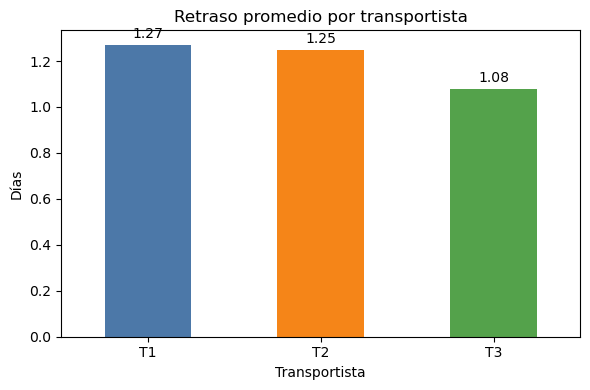

In [12]:
# --- GRÁFICO 1: retraso promedio por transportista ---
fig, ax = plt.subplots(figsize=(6, 4))
por_transp["retraso_prom_dias"].plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518", "#54A24B"])
ax.set_title("Retraso promedio por transportista")
ax.set_ylabel("Días")
ax.set_xlabel("Transportista")
for i, v in enumerate(por_transp["retraso_prom_dias"]):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center")   # etiqueta con el valor sobre cada barra
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../graficos/ej3_retraso_por_transportista.png", dpi=150)
plt.show()

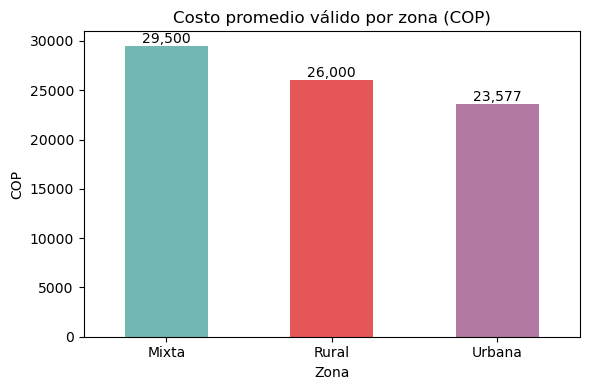

In [13]:
# --- GRÁFICO 2: costo promedio válido por zona ---
fig, ax = plt.subplots(figsize=(6, 4))
costo_zona.plot(kind="bar", ax=ax, color=["#72B7B2", "#E45756", "#B279A2"])
ax.set_title("Costo promedio válido por zona (COP)")
ax.set_ylabel("COP")
ax.set_xlabel("Zona")
for i, v in enumerate(costo_zona):
    ax.text(i, v + 300, f"{v:,.0f}", ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../graficos/ej3_costo_por_zona.png", dpi=150)
plt.show()

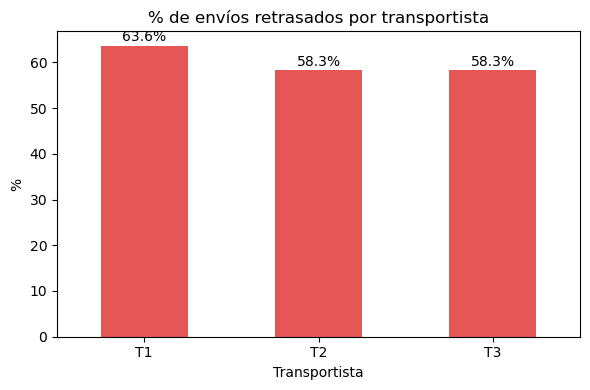

In [14]:
# --- GRÁFICO 3: % de retrasos por transportista ---
fig, ax = plt.subplots(figsize=(6, 4))
por_transp["pct_retrasos"].plot(kind="bar", ax=ax, color="#E45756")
ax.set_title("% de envíos retrasados por transportista")
ax.set_ylabel("%")
ax.set_xlabel("Transportista")
for i, v in enumerate(por_transp["pct_retrasos"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../graficos/ej3_pct_retrasos_transportista.png", dpi=150)
plt.show()

## Anomalías detectadas (documentar en el informe)
| ID | Anomalía | Tratamiento |
|---|---|---|
| E010 | Zona escrita `' urbana '` (espacios y minúscula) | Normalizada a `Urbana` |
| E022 | Costo negativo (−5.000 COP) | Marcado como NaN (inválido); no se inventa un valor |
| E030 | `Dias_Reales` vacío | Retraso queda NaN; se excluye del conteo de a tiempo/retrasadas |

## Decisión gerencial
Se completa en el informe con los números de las tablas anterior (ver resumen de resultados).